### 常见的Loader加载器：系统的IO接口 
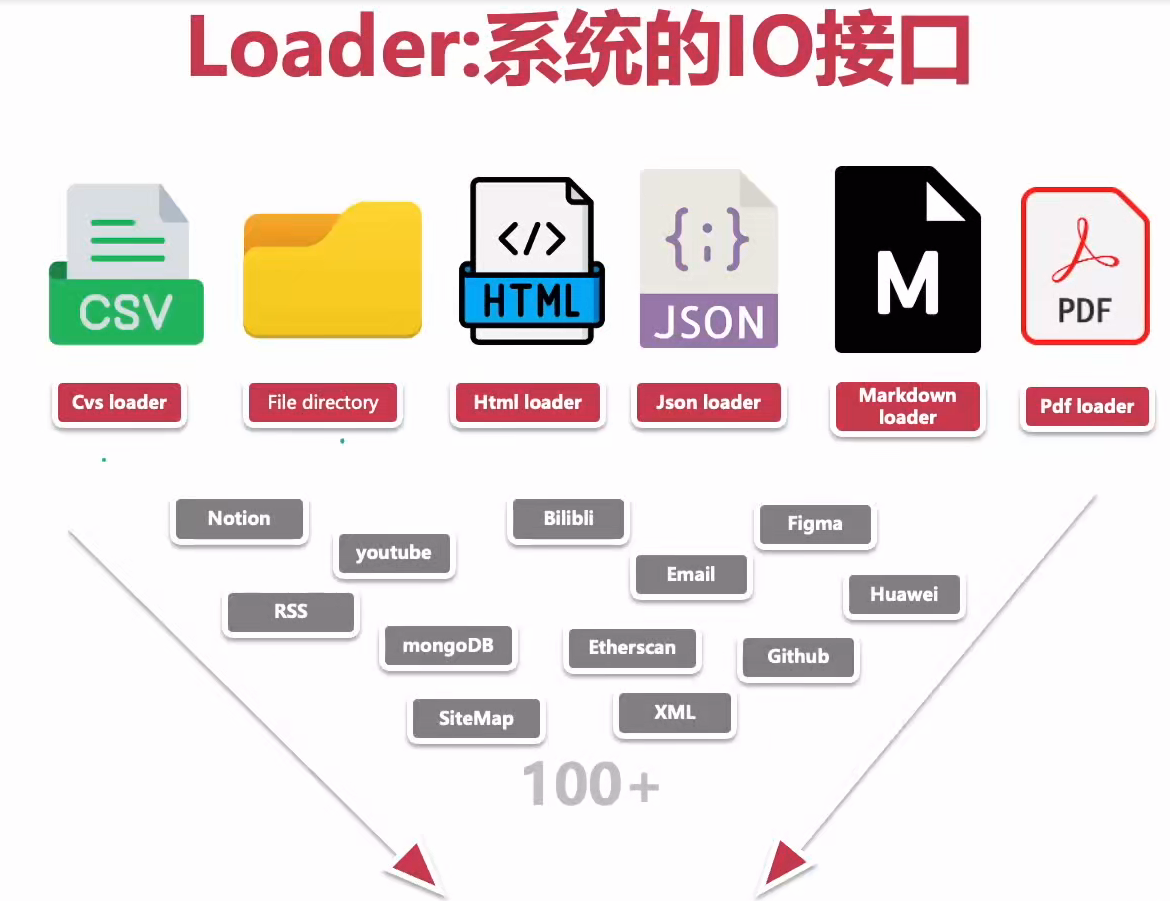  

Loader将各种结构化与非结构化数据加载进系统，并最终统一向量化

### 常见的Loader加载器
---
1. 如何加载PDF
2. 如何加载网页
3. 如何加载CSV以及Excel
4. 如何自定义一个文件加载器

#### 如何加载PDF
---

In [1]:
! pip install langchain_community


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
! pip install pypdf


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from langchain_community.document_loaders import PyPDFLoader

file_path='math.pdf'
loader = PyPDFLoader(file_path)
pages = []
async for page in loader.alazy_load():
    pages.append(page)

C:\Users\Lxb\AppData\Local\Temp\ipykernel_64744\3696177916.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
import asyncio
from pypdf import PdfReader
from langchain_core.documents import Document

async def load_pdf_async(file_path: str):
    """异步加载 PDF 文件"""
    # pypdf 是同步库，使用 asyncio.to_thread 放入线程池执行，避免阻塞异步事件循环
    def _read_pdf():
        reader = PdfReader(file_path)
        docs = []
        for i, page in enumerate(reader.pages):
            text = page.extract_text()
            # 构建 LangChain 标准的 Document 对象
            docs.append(Document(
                page_content=text,
                metadata={"source": file_path, "page": i + 1}
            ))
        return docs
    
    return await asyncio.to_thread(_read_pdf)

# 使用示例
async def main():
    file_path = 'math.pdf'
    pages = await load_pdf_async(file_path)
    print(f"成功加载 {len(pages)} 页")
    print(f"第一页内容预览: {pages[0].page_content[:100]}...")

# 如果在 Jupyter Notebook 中，可以直接运行：
# await main()
# 如果在普通 Python 脚本中，请使用：
# asyncio.run(main())

In [5]:
print(f"{pages[1].metadata}\n")
print(pages[1].page_content)

{'producer': 'Microsoft® Word 2013', 'creator': 'Microsoft® Word 2013', 'creationdate': '2014-09-12T16:00:04+08:00', 'title': '常量与变量', 'author': '秋\u3000风\u3000辞', 'moddate': '2014-09-12T16:00:04+08:00', 'source': 'math.pdf', 'total_pages': 95, 'page': 1, 'page_label': '2'}

2 
一、函数与极限 
1、集合的概念 
一般地我们把研究对象统称为元素，把一些元素组成的总体叫集合（简称集）。集合具有确定性（给
定集合的元素必须是确定的）和互异性（给定集合中的元素是互不相同的）。比如“身材较高的人”不能
构成集合，因为它的元素不是确定的。 
我们通常用大字拉丁字母 A、B、C、……表示集合，用小写拉丁字母 a、b、c……表示集合中的元素。
如果 a是集合 A中的元素，就说 a属于 A，记作：a∈A，否则就说 a 不属于 A，记作：a A。 
⑴、全体非负整数组成的集合叫做非负整数集（或自然数集）。记作 N 
⑵、所有正整数组成的集合叫做正整数集。记作 N+或 N+。 
⑶、全体整数组成的集合叫做整数集。记作 Z。 
⑷、全体有理数组成的集合叫做有理数集。记作 Q。 
⑸、全体实数组成的集合叫做实数集。记作 R。 
集合的表示方法 
⑴、列举法：把集合的元素一一列举出来，并用“｛｝”括起来表示集合 
⑵、描述法：用集合所有元素的共同特征来表示集合。 
集合间的基本关系 
⑴、子集：一般地，对于两个集合 A、B，如果集合 A中的任意一个元素都是集合 B 的元素，我们就
说 A、B有包含关系，称集合 A为集合 B 的子集，记作 A B（或 B A）。。 
⑵相等：如何集合 A是集合 B的子集，且集合 B是集合 A的子集，此时集合 A中的元素与集合 B 中
的元素完全一样，因此集合 A与集合 B相等，记作 A＝B。 
⑶、真子集：如何集合A是集合 B的子集，但存在一个元素属于 B但不属于 A，我们称集合 A是集合
B的真子集。 
⑷、空集：我们把不含任何元素的集合叫做空集。记作 ，并规定，空集是任何集合的子集。

#### 多模态模型解析PDF
---


In [6]:
! pip install -qU PyMuPDF pillow langchain-openai IPython

  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


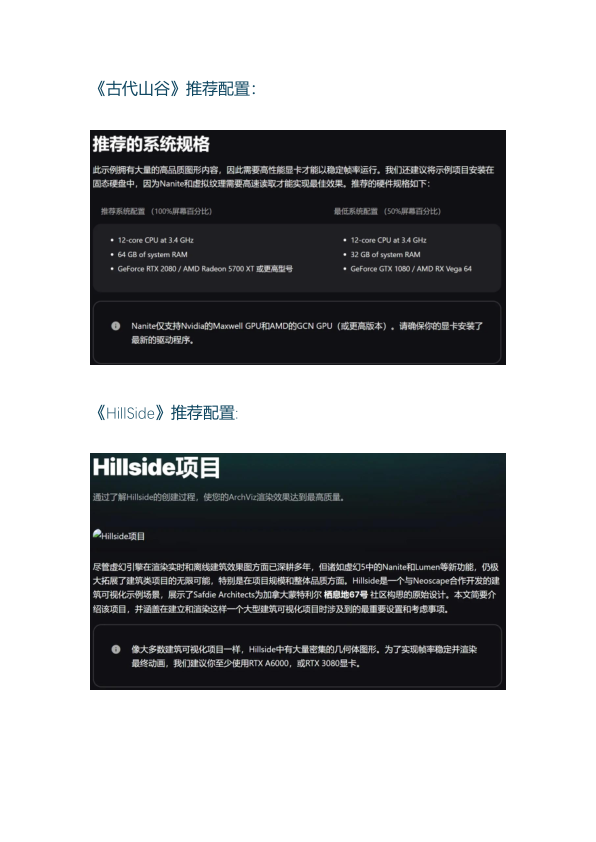

In [16]:
import base64
import io

import fitz
from PIL import Image
from IPython.display import Image as IPImage
from IPython.display import display

file_path='fake.pdf'

# 将pdf中的图片转成base64
def pdf_page_to_base64(pdf_path:str, page_number:int):
    page_document = fitz.open(pdf_path)
    page = page_document.load_page(page_number - 1)  # input is one-indexed
    pix = page.get_pixmap()
    img = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)

    buffer = io.BytesIO()
    img.save(buffer, format="PNG")

    return base64.b64encode(buffer.getvalue()).decode("utf-8")

base64_image = pdf_page_to_base64(file_path, 8)
display(IPImage(data=base64.b64decode(base64_image)))


使用多模态

In [20]:
from langchain_core.messages import HumanMessage
from dotenv import load_dotenv
import os

load_dotenv()

from langchain_openai import ChatOpenAI
import os
llm = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

query = "推荐的系统规格是什么样？"

message = HumanMessage(
    content=[
        {"type": "text", "text": query},
        {
            "type":"image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{base64_image}"},
        },
    ],
)

response = llm.invoke([message])

print(response.content)




根据图片，明确以“**推荐的系统规格**”为标题的是《古代山谷》项目，它把硬件要求分成了两档（推荐 / 最低），并附了额外说明：

**推荐系统配置（100% 屏幕百分比）**
- 12 核 CPU，主频 3.4 GHz
- 64 GB 系统内存（RAM）
- GeForce RTX 2080 / AMD Radeon 5700 XT 或更高型号

**最低系统配置（50% 屏幕百分比）**
- 12 核 CPU，主频 3.4 GHz
- 32 GB 系统内存（RAM）
- GeForce GTX 1080 / AMD RX Vega 64

**配套建议 / 注意事项**
- 该示例包含大量高品质图形内容，需要高性能显卡才能稳定帧率；建议把项目装在**固态硬盘**上，因为 Nanite 和虚拟纹理依赖高速读取才能达到最佳效果。
- Nanite 仅支持 Nvidia 的 Maxwell GPU 和 AMD 的 GCN GPU（或更高版本），请确保显卡已安装**最新驱动程序**。

另外，图片下半部分的《HillSide》项目没有给出完整的硬件表格，只针对显卡做了推荐：由于场景含大量复杂几何体，为稳定帧率并渲染最多动画，**至少使用 RTX A6000 或 RTX 3080 显卡**。

简单说：如果你要按“推荐规格”配机器，核心就是 **12 核 3.4 GHz CPU + 64 GB 内存 + RTX 2080 / RX 5700 XT 级别以上的显卡**，并尽量用 SSD。
